<a href="https://colab.research.google.com/github/KrFrandsen/GoogleColab/blob/main/GH38_A_Glycan_Interactions_Chai_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predict Protein Glycan Interactions

This notebook demonstrates how to use Chai-1, a powerful tool for protein structure prediction, including predictions for ligand interaction. You can either use a pre-trained model or fine-tune it with your own data. This notebook will guide you through checking GPU availability, installing necessary packages, preparing input data, running inference, and visualizing the results.

In [ ]:
# @title Check GPUs
!nvidia-smi

Wed Oct 21 17:38:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   32C    P0             55W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [ ]:
# @title Install Chai-1. (this will take about 10 min the first time)
!pip install -q chai_lab==0.6.1
# For the bleeding-edge version instead, comment the line above and uncomment below:
# !pip install -q git+https://github.com/chaidiscovery/chai-lab.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 132.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 105.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 416.5/416.5 kB 42.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.1/172.1 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 124.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 kB 5.4 MB/s eta 0:0

#  In case of dependency conflicts: **Restart the session**

(Chai-1 pulls NumPy v.1.26.4 as part of the dependencies, which can result in conflicts with other packages)

In [ ]:
# @title Check that you have chai-lab in /usr/local/bin/
!which chai-lab

/usr/local/bin/chai-lab


---


# **Predict Protein Glycan Interactions**

## ***(If it crashes due to depleting the System RAM -> Restart the Session)***

## Here you can model protein domains in complex with a carbohydrate substrate.

## Examples of glycan substrates from reducing to non-reducing end:
1) Mannan : *BMA(4-1 BMA(4-1 BMA(4-1 BMA)))*
2) Glucomannan : *BMA(4-1 BGC(4-1 BMA(4-1 BGC)))*
3) Glucan (cellulose) : *BGC(4-1 BGC(4-1 BGC(4-1 BGC)))*

## Examples of glycan substrates from non-reducing to reducing end:
4) Galactoxyloglucan: BGC(1-4 BGC(1-4 BGC(6-1 XYS(2-1 GAL))(1-4 BGC(1-4 BGC))))

.

**(HINT: If you only have access to mininmal resources -> choose short (<300 aa) protein sequences to avoid the runtime from crashing from too little RAM)**


In [ ]:
# @title #### Retrieve Protein Sequence from PDB
import requests
import os

# --- CONFIGURATION ---
# Enter one or multiple PDB IDs separated by a comma (e.g., "3qho, 5acf").
# By default, the script retrieves Chain A.
# If you need to specify a custom chain, append an underscore and the chain letter (e.g., "3qho_b, 5acf_a").
pdb_id = "" # @param {type:"string"}
# ---------------------

retrieved_sequences = []
pdb_fastas = []

if pdb_id.strip():
    # Split by comma and clean whitespace
    pdb_terms = [t.strip().upper() for t in pdb_id.split(",") if t.strip()]
    default_chain = "A"

    for term in pdb_terms:
        # Check if user specified a chain via underscore (e.g., 5ACF_B)
        if "_" in term:
            pid, target_chain = term.split("_", 1)
        else:
            pid = term
            target_chain = default_chain

        print(f"Retrieving chain-to-entity mapping for PDB {pid} (target chain: {target_chain})...")
        url_entry = f"https://data.rcsb.org/rest/v1/core/entry/{pid}"
        try:
            res_entry = requests.get(url_entry)
            if res_entry.status_code == 200:
                entry_data = res_entry.json()
                polymer_entities = entry_data.get("rcsb_entry_container_identifiers", {}).get("polymer_entity_ids", [])

                seq_found = False
                for ent_id in polymer_entities:
                    url_entity = f"https://data.rcsb.org/rest/v1/core/polymer_entity/{pid}/{ent_id}"
                    res_entity = requests.get(url_entity)
                    if res_entity.status_code == 200:
                        ent_data = res_entity.json()
                        container_ids = ent_data.get("rcsb_polymer_entity_container_identifiers", {})
                        auth_ids = container_ids.get("auth_asym_ids", [])
                        label_ids = container_ids.get("asym_ids", [])

                        # Normalize to compare securely
                        auth_ids_upper = [a.upper() for a in auth_ids]
                        label_ids_upper = [l.upper() for l in label_ids]

                        if target_chain in auth_ids_upper or target_chain in label_ids_upper:
                            protein_seq = ent_data.get("entity_poly", {}).get("pdbx_seq_one_letter_code", "")
                            if protein_seq:
                                header_info = f"protein|PDB_{pid}_Chain_{target_chain}"
                                retrieved_sequences.append((term, header_info, protein_seq))
                                print(f"-> Sequence for {pid} chain {target_chain} successfully retrieved!")
                                seq_found = True
                                break
                if not seq_found:
                    print(f"-> Could not find chain {target_chain} in PDB {pid}.")
            else:
                print(f"-> Could not find PDB entry {pid} (Status code: {res_entry.status_code}).")
        except Exception as e:
            print(f"-> Error retrieving PDB {pid}: {e}")

if retrieved_sequences:
    # Use the first retrieved protein as primary global targets to support existing downstream workflow fallback
    globals()["header_info"] = retrieved_sequences[0][1]
    globals()["protein_seq"] = retrieved_sequences[0][2]

    print("\nSaving individual sequences to list 'pdb_fastas' (no files written)...")
    for term, header, seq in retrieved_sequences:
        filename = f"{term.lower()}_seq.fasta"
        fasta_content = f">{header}\n{seq}\n"
        pdb_fastas.append((filename, fasta_content))
        print(f"-> Added to list: {filename}")

    globals()["pdb_fastas"] = pdb_fastas
else:
    globals()["pdb_fastas"] = []
    print("No sequences retrieved.")

No sequences retrieved.


In [ ]:
# @title Input Protein Sequence
import ipywidgets as widgets
from IPython.display import display, clear_output
import os

# Create a multi-line text area for pasting FASTA sequences
seq_textarea = widgets.Textarea(
    placeholder='Paste your FASTA sequences here...\ne.g.\n>protein|My_Protein_1\nMEGS...\n>protein|My_Protein_2\nMSNW...',
    description='FASTA Input:',
    layout=widgets.Layout(width='100%', height='200px')
)

save_button = widgets.Button(
    description='Process Sequences',
    button_style='success',
    tooltip='Click to parse and store each sequence in user_fastas list'
)

output_area = widgets.Output()

def on_save_clicked(b):
    with output_area:
        clear_output()
        fasta_sequences_input = seq_textarea.value.strip()

        if not fasta_sequences_input:
            print("Error: The text box is empty! Please paste a sequence.")
            return

        print("Parsing pasted FASTA sequences...")
        lines = fasta_sequences_input.splitlines()

        parsed_proteins = []
        current_header = ""
        current_seq = []

        for line in lines:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if current_header and current_seq:
                    parsed_proteins.append((current_header, "".join(current_seq)))
                current_header = line.lstrip(">")
                current_seq = []
            else:
                current_seq.append(line)

        # Add the final parsed sequence if exists
        if current_header and current_seq:
            parsed_proteins.append((current_header, "".join(current_seq)))

        if parsed_proteins:
            user_fastas = []
            for idx, (header, seq) in enumerate(parsed_proteins):
                # Strip whitespaces and format accurately with proper standard linebreaks
                clean_seq = seq.replace(" ", "").replace("\n", "").upper()

                # Create clean identifier name for display label
                sanitized_name = ""
                for c in (header.split("|")[-1] if "|" in header else f"seq_{idx+1}"):
                    if c.isalnum() or c in ('_', '-'):
                        sanitized_name += c
                sanitized_name = sanitized_name.strip()
                filename = f"input_protein_{sanitized_name}.fasta"

                # Clean up potential leading/trailing whitespaces in headers too
                clean_header = header.strip()

                # Ensure we format with exact clean single trailing linebreaks
                fasta_content = f">{clean_header}\n{clean_seq}\n"
                user_fastas.append((filename, fasta_content))

            # Save globally to user_fastas
            globals()["user_fastas"] = user_fastas

            # Keep backward compatibility with existing downstream fallback variables
            globals()["protein_seq"] = parsed_proteins[0][1].replace(" ", "").upper()
            globals()["header_info"] = parsed_proteins[0][0]

            print(f"\nSuccess! Successfully added {len(user_fastas)} protein sequences to list 'user_fastas' (no files written to disk):\n")
            for filename, content in user_fastas:
                print(f"-> Added: {filename}")
        else:
            print("Error: No valid protein sequence parsed. Please ensure the pasted text starts with a FASTA header (e.g. >protein|name).")

save_button.on_click(on_save_clicked)

# Display the widget elements
display(widgets.VBox([
    widgets.HTML("<h4><b>Paste FASTA Protein Sequences</b></h4>"),
    seq_textarea,
    save_button,
    output_area
]))

In [ ]:
# @title Full List of Sequences
# Retrieve both protein lists from global namespace (default to empty list if not defined)
pdb_list = globals().get("pdb_fastas", [])
user_list = globals().get("user_fastas", [])

# Merge lists together
all_protein_fastas = pdb_list + user_list
globals()["all_protein_fastas"] = all_protein_fastas

# Join and display the clean, sequential FASTA sequence data cleanly
combined_fasta_str = ""
for filename, content in all_protein_fastas:
    combined_fasta_str += content

print(combined_fasta_str.strip())

In [ ]:
# @title
!pip install glycowork
import glycowork

In [ ]:
# @title Interactive Glycan Constructor
!pip install -q glycowork
import ipywidgets as widgets
from IPython.display import display, clear_output
from glycowork.motif.draw import GlycoDraw
import os

# Define available monomers using SNFG nomenclature with full names and PDB identifiers in parentheses
monomers_info = [
    # Hexoses
    ("β-Glcp (beta-D-glucopyranose, BGC)", "Glcp"),
    ("β-Galp (beta-D-galactopyranose, GAL)", "Galp"),
    ("α-Manp (alpha-D-mannopyranose, MAN)", "Manp"),
    ("β-Manp (beta-D-mannopyranose, BMA)", "Manp_beta"),
    ("β-Allp (beta-D-allopyranose, ALL)", "Allp"),
    ("β-Altp (beta-D-altropyranose, ALT)", "Altp"),
    ("α-Gulp (alpha-D-gulopyranose, GUL)", "Gulp"),
    ("α-Idop (alpha-D-idopyranose, IDO)", "Idop"),
    ("β-Talp (beta-D-talopyranose, TAL)", "Talp"),
    # Hexosamines
    ("β-GlcpNAc (N-acetyl-beta-D-glucosamine, NAG)", "GlcpNAc"),
    ("β-GalpNAc (N-acetyl-beta-D-galactosamine, NGA)", "GalpNAc"),
    ("β-ManpNAc (N-acetyl-beta-D-mannosamine, BM3)", "ManpNAc"),
    ("β-AllpNAc (N-acetyl-beta-D-allosamine, NAA)", "AllpNAc"),
    ("β-AltpNAc (N-acetyl-beta-D-altrosamine, NAB)", "AltpNAc"),
    ("β-GulpNAc (N-acetyl-beta-D-gulosamine, NGB)", "GulpNAc"),
    ("β-IdopNAc (N-acetyl-beta-D-idosamine, NEG)", "IdopNAc"),
    ("β-TalpNAc (N-acetyl-beta-D-talosamine, NDE)", "TalpNAc"),
    # Hexuronates
    ("β-GlcpA (beta-D-glucuronic acid, BDP)", "GlcpA"),
    ("β-GalpA (beta-D-galacturonic acid, GAL)", "GalpA"),
    ("α-ManpA (alpha-D-mannuronic acid, MAV)", "ManpA"),
    ("β-AllpA (beta-D-alluronic acid, ALL)", "AllpA"),
    ("β-AltpA (beta-D-altruronic acid, ALT)", "AltpA"),
    ("α-GulpA (alpha-D-guluronic acid, GUL)", "GulpA"),
    ("α-IdopA (alpha-L-iduronic acid, IDO)", "IdopA"),
    ("β-TalpA (beta-D-taluronic acid, TAL)", "TalpA"),
    # Deoxyhexoses
    ("α-Fucp (alpha-L-fucopyranose, FUC)", "Fucp"),
    ("α-Rhap (alpha-L-rhamnopyranose, RHA)", "Rhap"),
    ("β-Quip (beta-D-quinovose, QUI)", "Quip"),
    # Pentoses
    ("β-Xylp (beta-D-xylopyranose, XYS)", "Xylp"),
    ("α-Arap (alpha-L-arabinopyranose, ARA)", "Arap"),
    ("β-Ribf (beta-D-ribofuranose, RIB)", "Ribf"),
    ("β-Lyxp (beta-D-lyxopyranose, LYX)", "Lyxp"),
    # Nonulosonates / Sialic Acids
    ("Neu5Ac (N-acetylneuraminic acid, SIA)", "Neu5Ac"),
    ("Neu5Gc (N-glycolylneuraminic acid, NGC)", "Neu5Gc"),
    ("Kdn (ketodeoxynonulosonic acid, KDN)", "Kdn"),
    ("Kdo (ketodeoxyoctulosonic acid, KDO)", "Kdo")
]

linkages = ["(b1-4)", "(b1-3)", "(a1-3)", "(a1-6)", "(a2-3)", "(a2-6)", "(b1-2)", "(b1-6)"]

num_glycans_select = widgets.Dropdown(
    options=[1, 2, 3, 4, 5],
    value=2,
    description="No. Glycans:"
)

save_strings_btn = widgets.Button(
    description="Save Glycan Strings",
    button_style="success",
    tooltip="Click to save both IUPAC and Chai-1 strings to glycan_sequences.txt"
)

builder_container = widgets.VBox([])
output_panel = widgets.Output()

def translate_to_nested_chai(monomers_list, linkages_list):
    mapping = {
        "Glcp": "BGC",
        "Galp": "GAL",
        "Manp": "MAN",
        "Manp_beta": "BMA",
        "Xylp": "XYS",
        "Fucp": "FUC",
        "GlcpNAc": "NAG",
        "GalpNAc": "NGA",
        "Neu5Ac": "SIA",
        "Neu5Gc": "NGC",
        "GlcpA": "BDP",
        "GalpA": "GAL",
        "ManpA": "MAV",
        "Rhap": "RHA",
        "Arap": "ARA",
        "Ribf": "RIB",
        "Kdn": "KDN",
        "Kdo": "KDO"
    }

    clean_linkages = []
    for l in linkages_list:
        link = l.replace("(", "").replace(")", "")
        if len(link) >= 3:
            link = link[1:]
        clean_linkages.append(link)

    translated_monomers = []
    for m in monomers_list:
        core_m = m[2:] if (m.startswith("D-") or m.startswith("L-")) else m
        mapped = mapping.get(core_m, core_m.upper()[:3])
        translated_monomers.append(mapped)

    result = translated_monomers[0]
    for i in range(len(clean_linkages)):
        result += f"({clean_linkages[i]} {translated_monomers[i+1]}"
    result += ")" * len(clean_linkages)
    return result

def update_visualization(*args):
    with output_panel:
        clear_output(wait=True)

        glycans_iupac = []
        glycans_chai = []

        for i, widgets_group in enumerate(all_builders_widgets):
            if not widgets_group:
                continue

            temp_m = []
            temp_l = []

            j = 0
            while j < len(widgets_group):
                monomer_val = widgets_group[j].value
                clean_name = monomer_val.split("_")[0] if "_" in monomer_val else monomer_val
                isomer_val = "L" if clean_name in ["Fucp", "Rhap", "Arap", "IdopA"] else "D"
                temp_m.append(f"{isomer_val}-{monomer_val}")

                if j + 1 < len(widgets_group):
                    temp_l.append(widgets_group[j+1].value)
                    j += 2
                else:
                    j += 1

            m_list = temp_m
            l_list = temp_l

            glycan_str = m_list[0]
            for k in range(len(l_list)):
                glycan_str += f"{l_list[k]}{m_list[k+1]}"

            vis_glycan_str = glycan_str.replace("_beta", "").replace("p", "").replace("f", "")
            chai_format = translate_to_nested_chai(m_list, l_list)

            glycans_iupac.append(glycan_str)
            glycans_chai.append(chai_format)

            print(f"--- Glycan {i+1} (DP {len(m_list)}) ---")
            print(f"IUPAC (Non-Reducing -> Reducing): {glycan_str}")
            print(f"Chai-1 (Nested): {chai_format}\n")

            try:
                drawing = GlycoDraw(vis_glycan_str, suppress=False)
                display(drawing)
            except Exception as e:
                print(f"Could not generate SNFG visualization for Glycan {i+1}: {e}")
            print("="*50)

        globals()["glycan_to_visualize"] = glycans_iupac[0] if len(glycans_iupac) > 0 else ""
        globals()["glycan_sequence"] = glycans_chai[0] if len(glycans_chai) > 0 else ""
        globals()["all_glycans_iupac"] = glycans_iupac
        globals()["all_glycans_chai"] = glycans_chai

def save_sequences_to_file(b):
    with output_panel:
        iupac_list = globals().get("all_glycans_iupac", [])
        chai_list = globals().get("all_glycans_chai", [])
        if not iupac_list:
            print("No glycan sequences constructed to save yet.")
            return
        with open("glycan_sequences.txt", "w") as f:
            f.write("=== SAVED GLYCAN STRINGS ===\n\n")
            for idx, (iupac, chai) in enumerate(zip(iupac_list, chai_list)):
                f.write(f"Glycan {idx+1}:\n")
                f.write(f"  IUPAC:  {iupac}\n")
                f.write(f"  Chai-1: {chai}\n\n")
        print("\n[Saved] Success! All configurations saved to 'glycan_sequences.txt'")

save_strings_btn.on_click(save_sequences_to_file)
all_builders_widgets = []

def build_interfaces(*args):
    global all_builders_widgets

    target_size = num_glycans_select.value
    all_builders_widgets = all_builders_widgets[:target_size]
    while len(all_builders_widgets) < target_size:
        all_builders_widgets.append([])

    children = []
    for i in range(target_size):
        dp_select = widgets.IntSlider(value=4, min=1, max=12, step=1, description=f"Length (DP):")
        glycan_box = widgets.VBox([])

        def make_fields(change, g_box=glycan_box, idx=i):
            dp = change["new"] if isinstance(change, dict) else change
            fields = []
            widgets_group = []

            for step in range(dp):
                m_drop = widgets.Dropdown(
                    options=monomers_info,
                    value="Glcp",
                    description=f"Monomer {step+1}:"
                )
                widgets_group.append(m_drop)
                m_drop.observe(update_visualization, names="value")

                if step < dp - 1:
                    l_drop = widgets.Dropdown(
                        options=linkages,
                        value="(b1-4)" if step % 2 == 0 else "(b1-3)",
                        description=f"Linkage {step+1}:"
                    )
                    widgets_group.append(l_drop)
                    l_drop.observe(update_visualization, names="value")
                    fields.append(widgets.HBox([m_drop, l_drop]))
                else:
                    fields.append(widgets.HBox([m_drop]))

            all_builders_widgets[idx] = widgets_group
            g_box.children = fields
            update_visualization()

        def create_slider_callback(current_idx, current_box):
            return lambda change: make_fields(change["new"], g_box=current_box, idx=current_idx)

        dp_select.observe(create_slider_callback(i, glycan_box), names="value")

        make_fields(4, g_box=glycan_box, idx=i)

        section = widgets.VBox([
            widgets.HTML(f"<h5><b>Configure Glycan {i+1}</b></h5>"),
            dp_select,
            glycan_box
        ])
        children.append(section)

    builder_container.children = children
    update_visualization()

num_glycans_select.observe(build_interfaces, names="value")

# Display options with Save Button
controls = widgets.HBox([num_glycans_select, save_strings_btn])
display(controls, builder_container, output_panel)
build_interfaces()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


VBox()

Output()

In [ ]:
# @title Interactive Glycan Constructor - Builder Controls
!pip install -q glycowork
import ipywidgets as widgets
from IPython.display import display
import os

# Define available monomers using SNFG nomenclature with full names and PDB identifiers in parentheses
monomers_info = [
    # Hexoses
    ("β-Glcp (beta-D-glucopyranose, BGC)", "Glcp"),
    ("β-Galp (beta-D-galactopyranose, GAL)", "Galp"),
    ("α-Manp (alpha-D-mannopyranose, MAN)", "Manp"),
    ("β-Manp (beta-D-mannopyranose, BMA)", "Manp_beta"),
    ("β-Allp (beta-D-allopyranose, ALL)", "Allp"),
    ("β-Altp (beta-D-altropyranose, ALT)", "Altp"),
    ("α-Gulp (alpha-D-gulopyranose, GUL)", "Gulp"),
    ("α-Idop (alpha-D-idopyranose, IDO)", "Idop"),
    ("β-Talp (beta-D-talopyranose, TAL)", "Talp"),
    # Hexosamines
    ("β-GlcpNAc (N-acetyl-beta-D-glucosamine, NAG)", "GlcpNAc"),
    ("β-GalpNAc (N-acetyl-beta-D-galactosamine, NGA)", "GalpNAc"),
    ("β-ManpNAc (N-acetyl-beta-D-mannosamine, BM3)", "ManpNAc"),
    ("β-AllpNAc (N-acetyl-beta-D-allosamine, NAA)", "AllpNAc"),
    ("β-AltpNAc (N-acetyl-beta-D-altrosamine, NAB)", "AltpNAc"),
    ("β-GulpNAc (N-acetyl-beta-D-gulosamine, NGB)", "GulpNAc"),
    ("β-IdopNAc (N-acetyl-beta-D-idosamine, NEG)", "IdopNAc"),
    ("β-TalpNAc (N-acetyl-beta-D-talosamine, NDE)", "TalpNAc"),
    # Hexuronates
    ("β-GlcpA (beta-D-glucuronic acid, BDP)", "GlcpA"),
    ("β-GalpA (beta-D-galacturonic acid, GAL)", "GalpA"),
    ("α-ManpA (alpha-D-mannuronic acid, MAV)", "ManpA"),
    ("β-AllpA (beta-D-alluronic acid, ALL)", "AllpA"),
    ("β-AltpA (beta-D-altruronic acid, ALT)", "AltpA"),
    ("α-GulpA (alpha-D-guluronic acid, GUL)", "GulpA"),
    ("α-IdopA (alpha-L-iduronic acid, IDO)", "IdopA"),
    ("β-TalpA (beta-D-taluronic acid, TAL)", "TalpA"),
    # Deoxyhexoses
    ("α-Fucp (alpha-L-fucopyranose, FUC)", "Fucp"),
    ("α-Rhap (alpha-L-rhamnopyranose, RAM)", "Rhap"),
    ("β-Quip (beta-D-quinovose, QUI)", "Quip"),
    # Pentoses
    ("β-Xylp (beta-D-xylopyranose, XYS)", "Xylp"),
    ("α-Arap (alpha-L-arabinopyranose, ARA)", "Arap"),
    ("β-Ribf (beta-D-ribofuranose, RIB)", "Ribf"),
    ("β-Lyxp (beta-D-lyxopyranose, LYX)", "Lyxp"),
    # Nonulosonates / Sialic Acids
    ("Neu5Ac (N-acetylneuraminic acid, SIA)", "Neu5Ac"),
    ("Neu5Gc (N-glycolylneuraminic acid, NGC)", "Neu5Gc"),
    ("Kdn (ketodeoxynonulosonic acid, KDN)", "Kdn"),
    ("Kdo (ketodeoxyoctulosonic acid, KDO)", "Kdo")
]

linkages = ["(b1-4)", "(b1-3)", "(a1-3)", "(a1-6)", "(a2-3)", "(a2-6)", "(b1-2)", "(b1-6)"]

num_glycans_select = widgets.Dropdown(
    options=[1, 2, 3, 4, 5],
    value=2,
    description="No. Glycans:"
)

save_strings_btn = widgets.Button(
    description="Save Glycan Strings",
    button_style="success",
    tooltip="Click to save both IUPAC and Chai-1 strings to glycan_sequences.txt"
)

builder_container = widgets.VBox([])
output_panel = widgets.Output()

def translate_to_nested_chai(monomers_list, linkages_list):
    mapping = {
        "Glcp": "BGC",
        "Galp": "GAL",
        "Manp": "MAN",
        "Manp_beta": "BMA",
        "Xylp": "XYS",
        "Fucp": "FUC",
        "GlcpNAc": "NAG",
        "GalpNAc": "NGA",
        "Neu5Ac": "SIA",
        "Neu5Gc": "NGC",
        "GlcpA": "BDP",
        "GalpA": "GAL",
        "ManpA": "MAV",
        "Rhap": "RAM",
        "Arap": "ARA",
        "Ribf": "RIB",
        "Kdn": "KDN",
        "Kdo": "KDO"
    }

    clean_linkages = []
    for l in linkages_list:
        link = l.replace("(", "").replace(")", "")
        if len(link) >= 3:
            link = link[1:]
        clean_linkages.append(link)

    translated_monomers = []
    for m in monomers_list:
        core_m = m[2:] if (m.startswith("D-") or m.startswith("L-")) else m
        mapped = mapping.get(core_m, core_m.upper()[:3])
        translated_monomers.append(mapped)

    result = translated_monomers[0]
    for i in range(len(clean_linkages)):
        result += f"({clean_linkages[i]} {translated_monomers[i+1]}"
    result += ")" * len(clean_linkages)
    return result

def update_visualization(*args):
    # Hook for downstream rendering in the display cell
    if "trigger_render" in globals():
        globals()["trigger_render"]()

def save_sequences_to_file(b):
    with output_panel:
        iupac_list = globals().get("all_glycans_iupac", [])
        chai_list = globals().get("all_glycans_chai", [])
        if not iupac_list:
            print("No glycan sequences constructed to save yet.")
            return
        with open("glycan_sequences.txt", "w") as f:
            f.write("=== SAVED GLYCAN STRINGS ===\n\n")
            for idx, (iupac, chai) in enumerate(zip(iupac_list, chai_list)):
                f.write(f"Glycan {idx+1}:\n")
                f.write(f"  IUPAC:  {iupac}\n")
                f.write(f"  Chai-1: {chai}\n\n")
        print("\n[Saved] Success! All configurations saved to 'glycan_sequences.txt'")

save_strings_btn.on_click(save_sequences_to_file)
all_builders_widgets = []

def build_interfaces(*args):
    global all_builders_widgets

    target_size = num_glycans_select.value
    all_builders_widgets = all_builders_widgets[:target_size]
    while len(all_builders_widgets) < target_size:
        all_builders_widgets.append([])

    children = []
    for i in range(target_size):
        dp_select = widgets.IntSlider(value=4, min=1, max=12, step=1, description=f"Length (DP):")
        glycan_box = widgets.VBox([])

        def make_fields(change, g_box=glycan_box, idx=i):
            dp = change["new"] if isinstance(change, dict) else change
            fields = []
            widgets_group = []

            for step in range(dp):
                m_drop = widgets.Dropdown(
                    options=monomers_info,
                    value="Glcp",
                    description=f"Monomer {step+1}:"
                )
                widgets_group.append(m_drop)
                m_drop.observe(update_visualization, names="value")

                if step < dp - 1:
                    l_drop = widgets.Dropdown(
                        options=linkages,
                        value="(b1-4)" if step % 2 == 0 else "(b1-3)",
                        description=f"Linkage {step+1}:"
                    )
                    widgets_group.append(l_drop)
                    l_drop.observe(update_visualization, names="value")
                    fields.append(widgets.HBox([m_drop, l_drop]))
                else:
                    fields.append(widgets.HBox([m_drop]))

            all_builders_widgets[idx] = widgets_group
            g_box.children = fields
            update_visualization()

        def create_slider_callback(current_idx, current_box):
            return lambda change: make_fields(change["new"], g_box=current_box, idx=current_idx)

        dp_select.observe(create_slider_callback(i, glycan_box), names="value")
        make_fields(4, g_box=glycan_box, idx=i)

        section = widgets.VBox([
            widgets.HTML(f"<h5><b>Configure Glycan {i+1}</b></h5>"),
            dp_select,
            glycan_box
        ])
        children.append(section)

    builder_container.children = children
    update_visualization()

num_glycans_select.observe(build_interfaces, names="value")

controls = widgets.HBox([num_glycans_select, save_strings_btn])
display(controls, builder_container)
build_interfaces()

VBox()

In [ ]:
# @title Glycan Visualizer 2D
from IPython.display import display, clear_output
from glycowork.motif.draw import GlycoDraw

def render_glycans():
    with output_panel:
        clear_output(wait=True)
        glycans_iupac = []
        glycans_chai = []

        for i, widgets_group in enumerate(all_builders_widgets):
            if not widgets_group:
                continue

            temp_m = []
            temp_l = []
            j = 0
            while j < len(widgets_group):
                monomer_val = widgets_group[j].value
                clean_name = monomer_val.split("_")[0] if "_" in monomer_val else monomer_val
                isomer_val = "L" if clean_name in ["Fucp", "Rhap", "Arap", "IdopA"] else "D"
                temp_m.append(f"{isomer_val}-{monomer_val}")

                if j + 1 < len(widgets_group):
                    temp_l.append(widgets_group[j+1].value)
                    j += 2
                else:
                    j += 1

            m_list = temp_m
            l_list = temp_l

            glycan_str = m_list[0]
            for k in range(len(l_list)):
                glycan_str += f"{l_list[k]}{m_list[k+1]}"

            vis_glycan_str = glycan_str.replace("_beta", "").replace("p", "").replace("f", "")
            chai_format = translate_to_nested_chai(m_list, l_list)

            glycans_iupac.append(glycan_str)
            glycans_chai.append(chai_format)

            print(f"--- Glycan {i+1} (DP {len(m_list)}) ---")
            print(f"IUPAC (Non-Reducing -> Reducing): {glycan_str}")
            print(f"Chai-1 (Nested): {chai_format}\n")

            try:
                drawing = GlycoDraw(vis_glycan_str, suppress=False)
                display(drawing)
            except Exception as e:
                print(f"Could not generate SNFG visualization for Glycan {i+1}: {e}")
            print("="*50)

        globals()["glycan_to_visualize"] = glycans_iupac[0] if len(glycans_iupac) > 0 else ""
        globals()["glycan_sequence"] = glycans_chai[0] if len(glycans_chai) > 0 else ""
        globals()["all_glycans_iupac"] = glycans_iupac
        globals()["all_glycans_chai"] = glycans_chai

globals()["trigger_render"] = render_glycans
display(output_panel)
render_glycans()

Output()

In [ ]:
!more glycan_sequences.txt


more: cannot open glycan_sequences.txt: No such file or directory


In [ ]:
# @title
# ══════════════════════════════════════════════════════════════════
#  GLYCAN 3D-SNFG VISUALISER  —  Google Colab (single cell)
# ══════════════════════════════════════════════════════════════════

# ── 1. Install necessary libraries locally inside the environment ──
import subprocess, sys
print("Installing required Python packages locally...")
subprocess.run([sys.executable, "-m", "pip", "install",
                "glycosylator", "py3Dmol", "rdkit", "-q"],
               capture_output=True)

# ── 2. Read Glycans from glycan_sequences.txt ─────────────────────
import os
import re
import glycosylator as gl
import uuid
from IPython.display import display, HTML

iupac_sequences = []
if os.path.exists("glycan_sequences.txt"):
    with open("glycan_sequences.txt", "r") as f:
        content = f.read()
        # Find all IUPAC definitions
        matches = re.findall(r"IUPAC:\s+(\S+)", content)
        for m in matches:
            iupac_sequences.append(m.strip())

# Fallback if file is missing or empty
if not iupac_sequences:
    iupac_sequences = [
        "D-Glcp(b1-4)D-Glcp(b1-3)D-Glcp(b1-4)D-Glcp",
        "D-Glcp(b1-4)D-Manp_beta(b1-4)D-Glcp(b1-4)D-Manp_beta(b1-4)D-Glcp"
    ]

print(f"Loaded {len(iupac_sequences)} glycan sequences from glycan_sequences.txt for 3D modeling.")

pdb_strings = []
labels = []

# Accurate GLYCAM to CCD mapping mapping depending on glycosylator output pattern
def convert_glycam_to_ccd(pdb_string: str) -> str:
    lines = []
    for line in pdb_string.splitlines():
        if line.startswith(("ATOM", "HETATM")):
            res_name = line[17:20].strip().upper()
            # Correctly identify sugar types to match official CCD codes
            if "GLC" in res_name:
                ccd = "GLC"
            elif "MAN" in res_name:
                ccd = "MAN"
            elif "GAL" in res_name:
                ccd = "GAL"
            elif "FUC" in res_name:
                ccd = "FUC"
            elif "XYL" in res_name:
                ccd = "XYL"
            elif "NAG" in res_name:
                ccd = "NAG"
            elif "SIA" in res_name or "NEU" in res_name:
                ccd = "SIA"
            else:
                # Fallback dictionary matching standard GLYCAM single letter identifiers
                glycam_lookup = {
                    "G": "GLC", "M": "MAN", "L": "GAL", "C": "MAN",
                    "Y": "NAG", "R": "NDG", "B": "NAG", "F": "FUC",
                    "S": "SIA", "V": "SIA", "X": "XYL", "A": "ARA",
                    "U": "GCU", "E": "GAL"
                }
                char_id = res_name[1] if len(res_name) == 3 else res_name[0]
                ccd = glycam_lookup.get(char_id, res_name)

            line = line[:17] + f"{ccd:<3}" + line[20:]
        lines.append(line)
    return "\n".join(lines)

# ── 3. Build 3D coordinates locally with glycosylator ─────────────
for idx, seq in enumerate(iupac_sequences):
    # Clean the sequence for compatibility with glycosylator IUPAC parser
    clean_iupac = seq.replace("D-", "").replace("L-", "")
    clean_iupac = clean_iupac.replace("Glcp", "Glc").replace("Galp", "Gal")
    clean_iupac = clean_iupac.replace("Manp_beta", "Man")
    clean_iupac = clean_iupac.replace("Manp", "Man")
    clean_iupac = clean_iupac.replace("Xylp", "Xyl").replace("Fucp", "Fuc")

    print(f"\nModeling Glycan {idx + 1}: {clean_iupac}")
    try:
        glycan = gl.glycan(clean_iupac)
        glycan.optimize()

        pdb_path = f"/tmp/seq_model_{idx}.pdb"
        glycan.to_pdb(pdb_path)

        with open(pdb_path) as fh:
            raw_pdb_string = fh.read()

        # Standardize the residue names to trigger official 3D-SNFG representations in Mol*
        ccd_pdb_string = convert_glycam_to_ccd(raw_pdb_string)
        pdb_strings.append(ccd_pdb_string)
        labels.append(f"Glycan {idx + 1}: {seq[:40]}...")
    except Exception as e:
        print(f"  [Error] Failed to build 3D model for Glycan {idx + 1}: {e}")

# ── 4. Render 3D views locally using CDN-hosted Mol* scripts ──────
uid = uuid.uuid4().hex[:10]

# Prepare Mol* script to load multiple models with official 3D-SNFG styles
load_models_js = ""
for idx, pdb_data in enumerate(pdb_strings):
    pdb_js = (pdb_data
              .replace("\\", "\\\\")
              .replace("`",  "\\`")
              .replace("$",  "\\$"))

    load_models_js += f"""
    // Setup model {idx}
    const pdbData_{idx} = `{pdb_js}`;
    const viewer_{idx} = await molstar.Viewer.create('viewer_{idx}_{uid}', {{
      layoutIsExpanded       : false,
      layoutShowControls     : false,
      layoutShowLeftPanel    : false,
      layoutShowLog          : false,
      layoutShowSequence     : false,
      viewportShowExpand     : false,
      viewportShowSelectionMode : false,
      viewportShowAnimation  : false,
    }});
    await viewer_{idx}.loadStructureFromData(pdbData_{idx}, 'pdb', {{
      dataLabel: 'Glycan {idx + 1}'
    }});
    const plugin_{idx} = viewer_{idx}.plugin;
    const structs_{idx} = plugin_{idx}.managers.structure.hierarchy.current.structures;
    if (structs_{idx}.length > 0) {{
      // Apply the official built-in Mol* 3D-SNFG preset
      await plugin_{idx}.managers.structure.component.applyPreset(
        structs_{idx}[0],
        'carbohydrate-and-sticks'
      );
    }}
    """

# Create side-by-side HTML container grid with robust spacing
html_grid = "<div style='display: flex; flex-wrap: wrap; gap: 20px; justify-content: center; background:#1a1a2e; padding:16px;'>"
for idx in range(len(pdb_strings)):
    html_grid += f"""
    <div style='border: 1px solid #444; border-radius: 8px; padding: 10px; background-color: #111; text-align: center; width: 380px;'>
        <div style='color: #65C5F4; font-family: sans-serif; font-size: 13px; font-weight: bold; margin-bottom: 8px; overflow: hidden; text-overflow: ellipsis; white-space: nowrap;'>
            {labels[idx]}
        </div>
        <div id='viewer_{idx}_{uid}' style='width: 360px; height: 360px; position: relative;'></div>
    </div>
    """
html_grid += "</div>"

# Inline viewer markup - completely avoids loopback port mapping
inline_html = f"""
<div style="width: 100%; height: 560px; background-color: #1a1a2e; border-radius: 8px; overflow: hidden;">
  <link rel="stylesheet" type="text/css" href="https://cdn.jsdelivr.net/npm/molstar@3.45.0/build/viewer/molstar.css">
  {html_grid}
  <script src="https://cdn.jsdelivr.net/npm/molstar@3.45.0/build/viewer/molstar.js"></script>
  <script>
  (async () => {{
    {load_models_js}
  }})().catch(err => {{
    console.error('Mol* failed:', err);
  }});
  </script>
</div>
"""

display(HTML(inline_html))

Installing required Python packages locally...
Loaded 2 glycan sequences from glycan_sequences.txt for 3D modeling.

Modeling Glycan 1: Glc(b1-4)Glc(b1-3)Glc(b1-4)Glc

Modeling Glycan 2: Glc(b1-4)Man(b1-4)Glc(b1-4)Man(b1-4)Glc


✓  Saved to /root/molstar_local  (5.1 MB)
Building: Complex N-glycan core  [GlcNAc(b1-2)Man(a1-6)[GlcNAc(b1-2)Man(a1-3)]Man(b1-4)GlcNAc(b1-4)GlcNAc]
✓  glycosylator residue codes: ['BMA', 'MAN', 'NAG', 'NDG']
✓  Renamed residues: {'NAG': 'ARA', 'BMA': 'MAN', 'MAN': 'ARA'}
✓  CCD residue codes for Mol*: ['ARA', 'MAN', 'NDG']


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning:

Consider using IPython.display.IFrame instead




── 2D SNFG ──────────────────────────────────────────────────


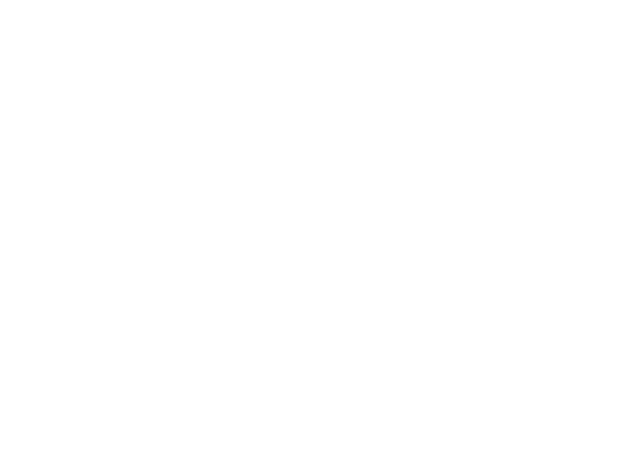

In [ ]:
# @title
# ══════════════════════════════════════════════════════════════════
#  GLYCAN 3D-SNFG  —  Mol* offline
#  • Cell 1 : one-time download of Mol* (~10 MB) → ~/molstar_local/
#  • Cell 2 : choose your glycan
#  • Cell 3 : build 3D coords with glycosylator (no internet)
#  • Cell 4 : fix residue names so Mol* recognises sugars
#  • Cell 5 : display with Mol* carbohydrate-and-sticks preset
#  • Cell 6 : 2D SNFG reference (glycowork)
# ══════════════════════════════════════════════════════════════════

# ── CELL 1 : install Python deps + download Mol* (run once) ──────
import subprocess, sys
subprocess.run(
    [sys.executable, "-m", "pip", "install",
     "glycosylator", "glycowork", "-q"],
    capture_output=True,
)

import os, urllib.request

MOLSTAR_DIR = os.path.expanduser("~/molstar_local")
os.makedirs(MOLSTAR_DIR, exist_ok=True)

JS_FILE  = os.path.join(MOLSTAR_DIR, "molstar.js")
CSS_FILE = os.path.join(MOLSTAR_DIR, "molstar.css")
VERSION  = "3.45.0"
BASE_URL = f"https://cdn.jsdelivr.net/npm/molstar@{VERSION}/build/viewer"

if not os.path.exists(JS_FILE):
    print(f"Downloading Mol* v{VERSION} — one-time, ~10 MB …")
    try:
        urllib.request.urlretrieve(f"{BASE_URL}/molstar.js",  JS_FILE)
        urllib.request.urlretrieve(f"{BASE_URL}/molstar.css", CSS_FILE)
        size_mb = os.path.getsize(JS_FILE) / 1e6
        print(f"✓  Saved to {MOLSTAR_DIR}  ({size_mb:.1f} MB)")
    except Exception as e:
        print(f"✗  Download failed: {e}")
        print("   → copy molstar.js + molstar.css manually to", MOLSTAR_DIR)
        raise
else:
    size_mb = os.path.getsize(JS_FILE) / 1e6
    print(f"✓  Mol* already cached  ({size_mb:.1f} MB)  —  {MOLSTAR_DIR}")

# ── CELL 2 : choose glycan ────────────────────────────────────────
EXAMPLES = {
    "Cellobiose"             : "Glc(b1-4)Glc",
    "Lactose"                : "Gal(b1-4)Glc",
    "LacNAc"                 : "Gal(b1-4)GlcNAc",
    "Mannobiose"             : "Man(a1-6)Man",
    "M3 core"                : "Man(a1-6)[Man(a1-3)]Man",
    "Complex N-glycan core"  : "GlcNAc(b1-2)Man(a1-6)[GlcNAc(b1-2)Man(a1-3)]Man(b1-4)GlcNAc(b1-4)GlcNAc",
    "High-mannose N-glycan"  : "Man(a1-2)Man(a1-6)[Man(a1-2)Man(a1-3)]Man(a1-6)[Man(a1-2)Man(a1-3)]Man(b1-4)GlcNAc(b1-4)GlcNAc",
    "Xyloglucan fragment"    : "Xyl(a1-6)Glc(b1-4)Glc",
    "Lewis X"                : "Fuc(a1-3)[Gal(b1-4)]GlcNAc",
}
CHOICE = "Complex N-glycan core"   # ← change this

# ── CELL 3 : build 3D structure (glycosylator, fully local) ───────
import glycosylator as gl
import base64
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from glycowork.motif.draw import GlycoDraw

iupac   = EXAMPLES[CHOICE]
print(f"Building: {CHOICE}  [{iupac}]")
glycan  = gl.glycan(iupac)
glycan.optimize()
pdb_path = f"/tmp/{CHOICE.replace(' ', '_')}.pdb"
glycan.to_pdb(pdb_path)
with open(pdb_path) as fh:
    pdb_raw = fh.read()

res_raw = sorted({ln[17:20].strip() for ln in pdb_raw.splitlines()
                   if ln.startswith(("ATOM","HETATM"))})
print(f"✓  glycosylator residue codes: {res_raw}")

# ── CELL 4 : GLYCAM → CCD residue rename ─────────────────────────
#  Mol* only shows SNFG symbols for standard CCD saccharide names.
#  glycosylator writes GLYCAM 3-char codes; we rename them here.
#  Middle character of GLYCAM code identifies the sugar type.

GLYCAM_CHAR_TO_CCD = {
    "G": "GLC",   # Glucose
    "M": "MAN",   # Mannose
    "L": "GAL",   # Galactose
    "C": "MAN",   # α-D-Man (GLYCAM alt)
    "Y": "NAG",   # GlcNAc
    "R": "NDG",   # GalNAc
    "B": "NAG",   # GlcNAc (alt)
    "F": "FUC",   # Fucose (α-L)
    "f": "FUC",   # Fucose (β, rare)
    "S": "SIA",   # NeuAc / Sialic acid
    "V": "SIA",   # NeuAc (alt)
    "X": "XYL",   # Xylose
    "A": "ARA",   # Arabinose
    "U": "GCU",   # GlcA
    "E": "GAL",   # Gal (alt)
    "J": "FRU",   # Fructose
    "K": "MAN",   # alt Man
    "N": "NAG",   # alt GlcNAc
    "P": "GLC",   # alt Glc
}

def glycam_to_ccd(pdb_string: str) -> tuple[str, dict]:
    """Rename GLYCAM residue codes to CCD codes in PDB text."""
    mapping = {}
    lines   = []
    for ln in pdb_string.splitlines():
        if ln.startswith(("ATOM","HETATM")):
            rn = ln[17:20].strip()
            if len(rn) == 3 and rn[1] in GLYCAM_CHAR_TO_CCD:
                ccd = GLYCAM_CHAR_TO_CCD[rn[1]]
                mapping[rn] = ccd
                ln = ln[:17] + f"{ccd:<3}" + ln[20:]
        lines.append(ln)
    return "\n".join(lines), mapping

pdb_ccd, rename_map = glycam_to_ccd(pdb_raw)
if rename_map:
    print("✓  Renamed residues:", rename_map)
else:
    print("✓  Residues already CCD format — no renaming needed")
    pdb_ccd = pdb_raw

# Verify final residue names
res_final = sorted({ln[17:20].strip() for ln in pdb_ccd.splitlines()
                     if ln.startswith(("ATOM","HETATM"))})
print(f"✓  CCD residue codes for Mol*: {res_final}")

# ── CELL 5 : Mol* viewer (offline, carbohydrate-and-sticks) ───────
with open(JS_FILE)  as fh: molstar_js  = fh.read()
with open(CSS_FILE) as fh: molstar_css = fh.read()

# Escape PDB for JS template literal
pdb_js = (pdb_ccd
          .replace("\\", "\\\\")
          .replace("`",  "\\`")
          .replace("$",  "\\$"))

molstar_html = f"""<!DOCTYPE html>
<html>
<head>
  <meta charset="utf-8">
  <style>
{molstar_css}
    html, body {{
      margin: 0; padding: 0;
      background: #1a1a2e;
      width: 100%; height: 100%;
    }}
    #viewer {{
      position: absolute;
      top: 0; left: 0; right: 0; bottom: 0;
    }}
  </style>
</head>
<body>
  <div id="viewer"></div>
  <script>
{molstar_js}
  </script>
  <script>
(async () => {{
  const viewer = await molstar.Viewer.create('viewer', {{
    layoutIsExpanded        : false,
    layoutShowControls      : false,
    layoutShowLeftPanel     : false,
    layoutShowLog           : false,
    layoutShowSequence      : false,
    viewportShowExpand      : false,
    viewportShowSelectionMode: false,
    viewportShowAnimation   : false,
  }});

  // Load PDB from embedded string
  await viewer.loadStructureFromData(`{pdb_js}`, 'pdb', {{
    dataLabel: '{CHOICE}'
  }});

  // Apply the 3D-SNFG carbohydrate preset
  const plugin  = viewer.plugin;
  const structs = plugin.managers.structure.hierarchy.current.structures;
  if (structs.length > 0) {{
    await plugin.managers.structure.component.applyPreset(
      structs[0],
      'carbohydrate-and-sticks'   // built-in Mol* 3D-SNFG preset
    );
  }}
}})().catch(err => {{
  document.body.innerHTML =
    '<pre style="color:#ff6b6b;padding:16px;font-size:13px;">'
    + '⚠  Mol* error:\\n' + err.stack + '</pre>';
}});
  </script>
</body>
</html>"""

# Embed as base64 data-URI iframe
# (works in JupyterLab + classic Notebook; avoids script-tag sanitisers)
b64 = base64.b64encode(molstar_html.encode()).decode()
display(HTML(
    f'<iframe src="data:text/html;base64,{b64}" '
    f'width="860" height="540" frameborder="0" '
    f'style="border-radius:6px; display:block;"></iframe>'
))

# ── CELL 6 : 2D SNFG reference ───────────────────────────────────
print("\n── 2D SNFG ──────────────────────────────────────────────────")
GlycoDraw(iupac)
plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# @title
import urllib.request
import json
import re
from bs4 import BeautifulSoup

url = "https://glycam.org/docs/othertoolsservice/2016/06/09/3d-snfg-list-of-residue-names/"
print(f"Fetching 3D-SNFG residue mapping data from: {url}")

try:
    # Fetch the webpage
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    req = urllib.request.Request(url, headers=headers)
    with urllib.request.urlopen(req) as response:
        html = response.read()

    # Parse tables with BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    mapping_data = {}

    # Locate all tables containing 3D-SNFG residue names
    tables = soup.find_all('table')
    print(f"Found {len(tables)} data table(s) on the page.")

    for idx, table in enumerate(tables):
        rows = table.find_all('tr')
        for row in rows:
            cols = [col.get_text().strip() for col in row.find_all(['td', 'th'])]
            if len(cols) >= 2:
                # Standardize mapping: Key is the 3-letter GLYCAM/PDB residue code, Value is the full SNFG standard name
                key = cols[0].upper()
                val = cols[1]
                # Filter out header rows like 'Residue Name' or empty indices
                if key and "RESIDUE" not in key and key != "CODE":
                    mapping_data[key] = val

    # Save the parsed mapping locally
    output_file = "glycam_3d_snfg_residues.json"
    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(mapping_data, f, indent=4, ensure_ascii=False)

    print(f"\nSuccess! Saved {len(mapping_data)} residue definitions to '{output_file}'")
    print("Preview of loaded mapping:")
    for k, v in list(mapping_data.items())[:10]:
        print(f"  {k} -> {v}")

except Exception as e:
    print(f"Error processing the URL: {e}")
    # Fallback backup database if network block or URL pattern changes
    fallback_mapping = {
        "BGC": "beta-D-glucopyranose",
        "GAL": "beta-D-galactopyranose",
        "MAN": "alpha-D-mannopyranose",
        "BMA": "beta-D-mannopyranose",
        "NAG": "N-acetyl-beta-D-glucosamine",
        "NGA": "N-acetyl-beta-D-galactosamine",
        "FUC": "alpha-L-fucopyranose",
        "XYL": "beta-D-xylopyranose",
        "SIA": "N-acetylneuraminic acid",
        "KDO": "ketodeoxyoctulosonic acid"
    }
    output_file = "glycam_3d_snfg_residues.json"
    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(fallback_mapping, f, indent=4)
    print(f"Saved offline fallback parameters to '{output_file}'")


Fetching 3D-SNFG residue mapping data from: https://glycam.org/docs/othertoolsservice/2016/06/09/3d-snfg-list-of-residue-names/
Found 3 data table(s) on the page.

Success! Saved 68 residue definitions to 'glycam_3d_snfg_residues.json'
Preview of loaded mapping:
  ABBREVIATION -> Full Name
  GLC -> Glucose
  GLCNAC -> N-Acetyl Glucosamine
  GLCN -> Glucosamine
  GLCA -> Glucuronic Acid
  QUI -> Quinovose
  QUINAC -> N-Acetyl Quinovosamine
  OLI -> Olivose
  MAN -> Mannose
  MANNAC -> N-Acetyl Mannosamine


In [ ]:
# @title Visualize Glycan Models with py3Dmol
!pip install -q py3Dmol biopython
import py3Dmol
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display
from Bio.PDB.MMCIFParser import MMCIFParser
import numpy as np

output_dir = Path("/content/output-glycans-only")

def display_glycan_model(model_idx=0):
    cif_files = sorted(output_dir.glob("pred.model_idx_*.cif"))
    if not cif_files:
        print(f"No CIF files found in {output_dir}.")
        return

    selected_model_path = cif_files[model_idx]
    print("Showing glycan model:", selected_model_path.name)

    # Try to load pLDDT values
    plddt_vals = None
    if 'candidates' in globals() and hasattr(candidates, 'plddt') and candidates.plddt is not None:
        plddt_vals = np.asarray(candidates.plddt[model_idx]).squeeze()
        if plddt_vals.max() <= 1.5:
            plddt_vals = plddt_vals * 100

    # Parse structure for chains
    parser = MMCIFParser(QUIET=True)
    structure = parser.get_structure("model", selected_model_path)
    model = structure[0]

    # In our run, Chain A is the dummy G residue, and subsequent chains are glycans
    has_a = 'A' in model
    has_b = 'B' in model

    view = py3Dmol.view(width=800, height=600)
    with open(selected_model_path) as f:
        view.addModel(f.read(), "cif")

    def get_plddt_color(score):
        if score >= 90: return "#0053D6" # Dark blue
        elif score >= 70: return "#65C5F4" # Light blue
        elif score >= 50: return "#FFDF00" # Yellow
        else: return "#FF6000" # Orange/Red

    # Style chains
    # Chain A (Single Glycine Anchor) is colored in grey
    if has_a:
        view.setStyle({"chain": "A"}, {"sphere": {"color": "#909090", "radius": 1.0}})

    # Glycan chains represented as thick sticks and colored by pLDDT if available
    for chain in model:
        chain_id = chain.get_id()
        if chain_id == 'A':
            continue

        # Style glycan residues
        residues = list(chain.get_residues())
        for r_idx, res in enumerate(residues):
            res_id = res.get_id()[1]
            if plddt_vals is not None:
                # Approximate the token mapping idx
                val_idx = 1 + r_idx  # 1 accounts for Chain A
                score = plddt_vals[val_idx] if val_idx < len(plddt_vals) else 60
                color = get_plddt_color(score)
            else:
                color = "#BA55D3" # Fallback Purple

            view.setStyle(
                {"chain": chain_id, "resi": str(res_id)},
                {"stick": {"color": color, "radius": 0.3}, "sphere": {"color": color, "radius": 0.4}}
            )

    view.zoomTo()
    view.show()

model_selector = widgets.IntSlider(
    min=0,
    max=4,
    step=1,
    description='Model Index:',
    value=0,
    continuous_update=False
)

display(widgets.interactive(display_glycan_model, model_idx=model_selector))

interactive(children=(IntSlider(value=0, continuous_update=False, description='Model Index:', max=4), Output()…

In [ ]:
# @title Interactive Protein & Glycan Combiner
import os
import ipywidgets as widgets
from IPython.display import display, clear_output
import shutil

# Retrieve sequences from the global variables
all_protein_fastas = globals().get('all_protein_fastas', [])
all_glycans_chai = globals().get('all_glycans_chai', [])
all_glycans_iupac = globals().get('all_glycans_iupac', [])

# Fallback defaults if list variables are empty
if not all_protein_fastas:
    fallback_seq = globals().get('protein_seq', 'MEGNTILKIVLICTILAGLFGQVVPVYAENTTYQTPTGIYYEVRGDTIYMINVTSGEETPIHLFGVNWF')
    fallback_header = globals().get('header_info', 'protein|Custom_Protein')
    all_protein_fastas = [("default_protein.fasta", f">{fallback_header}\n{fallback_seq}\n")]

if not all_glycans_chai:
    all_glycans_chai = [globals().get('glycan_sequence', 'BGC(1-4 BGC(1-4 BGC))')]
    all_glycans_iupac = [globals().get('glycan_to_visualize', 'Glc(b1-4)Glc(b1-4)Glc')]

# Helper to parse proteins inside the selection list
protein_options = []
for idx, (filename, content) in enumerate(all_protein_fastas):
    lines = content.strip().split('\n')
    header = lines[0].lstrip(">") if lines else f"Protein_{idx+1}"
    seq = "".join(lines[1:]) if len(lines) > 1 else ""
    label = f"{header} ({len(seq)} aa)"
    protein_options.append((label, (header, seq)))

# Widgets
protein_dropdown = widgets.Dropdown(
    options=protein_options,
    description='Protein:',
    layout=widgets.Layout(width='60%')
)

glycan_checkboxes = [
    widgets.Checkbox(
        value=True,
        description=f"Glycan {i+1}: {all_glycans_iupac[i] if i < len(all_glycans_iupac) else 'Custom'} ({seq})",
        layout=widgets.Layout(width='90%')
    )
    for i, seq in enumerate(all_glycans_chai)
]

merge_mode_toggle = widgets.ToggleButtons(
    options=['Separate files per glycan', 'All in one joint fasta', 'All-vs-All combination'],
    value='Separate files per glycan',
    description='Merge Mode:',
    button_style='info'
)

combine_button = widgets.Button(
    description='Generate Inference FASTA Files',
    button_style='success',
    tooltip='Click to pair chosen protein with selected glycans and write files'
)

out = widgets.Output()

def process_combination(b):
    with out:
        clear_output()
        selected_header, selected_seq = protein_dropdown.value
        selected_glycan_indices = [i for i, cb in enumerate(glycan_checkboxes) if cb.value]

        if not selected_glycan_indices:
            print("Error: Please select at least one glycan to model!")
            return

        mode = merge_mode_toggle.value

        if mode == "All-vs-All combination":
            print("Generating All-vs-All cross-pairing combinations for all proteins against selected glycans:\n")
            generated_files = []
            for p_idx, (p_filename, p_content) in enumerate(all_protein_fastas):
                p_lines = p_content.strip().split('\n')
                p_header = p_lines[0].lstrip(">") if p_lines else f"Protein_{p_idx+1}"
                p_seq = "".join(p_lines[1:]) if len(p_lines) > 1 else ""

                # Create clean label for file systems
                p_label = p_header.split('|')[-1].replace(' ', '_').replace('/', '_').replace(':', '_')

                for g_idx in selected_glycan_indices:
                    fasta_lines = [
                        f">{p_header}",
                        p_seq,
                        f">glycan|Glycan_{g_idx + 1}",
                        all_glycans_chai[g_idx]
                    ]
                    filename = f"input_all_vs_all_{p_label}_glycan_{g_idx + 1}.fasta"
                    fasta_content = "\n".join(fasta_lines) + "\n"
                    with open(filename, "w") as f:
                        f.write(fasta_content)
                    generated_files.append(filename)
                    print(f"--- Written to {filename} ---")
                    print(fasta_content)

            if generated_files:
                shutil.copy(generated_files[0], "input.fasta")
                print(f"[Info] Copied {generated_files[0]} to 'input.fasta' as default fallback target.")

        elif mode == "All in one joint fasta":
            fasta_lines = [f">{selected_header}", selected_seq]
            for idx in selected_glycan_indices:
                fasta_lines.append(f">glycan|Glycan_{idx + 1}")
                fasta_lines.append(all_glycans_chai[idx])

            fasta_content = "\n".join(fasta_lines) + "\n"
            with open("input.fasta", "w") as f:
                f.write(fasta_content)
            print("Generated a combined FASTA file (input.fasta):\n")
            print(fasta_content)
        else:
            print("Generated separate FASTA files for each selected glycan:\n")
            generated_files = []
            for loop_idx, idx in enumerate(selected_glycan_indices):
                fasta_lines = [
                    f">{selected_header}",
                    selected_seq,
                    f">glycan|Glycan_{idx + 1}",
                    all_glycans_chai[idx]
                ]
                filename = f"input_glycan_{idx + 1}.fasta"
                fasta_content = "\n".join(fasta_lines) + "\n"
                with open(filename, "w") as f:
                    f.write(fasta_content)
                generated_files.append(filename)
                print(f"--- Written to {filename} ---")
                print(fasta_content)

            # Update default fallback input.fasta
            if generated_files:
                shutil.copy(generated_files[0], "input.fasta")
                print(f"[Info] Copied {generated_files[0]} to 'input.fasta' as default inference target.")

combine_button.on_click(process_combination)

# Display Interface with a helpful warning notice explaining why only 1 glycan may show
display(widgets.VBox([
    widgets.HTML("<h3><b>Choose Protein & Glycans to Model</b></h3>"),
    widgets.HTML("<p style='color: gray; font-size: 12px;'><i>Note: Only seeing Glycan 1? Set 'No. Glycans' and click 'Save Glycan Strings' in cell eeWwACpSc9SR above, then rerun this cell.</i></p>"),
    protein_dropdown,
    widgets.HTML("<b>Select Glycans to Include:</b>"),
    widgets.VBox(glycan_checkboxes),
    widgets.Box([merge_mode_toggle], layout=widgets.Layout(margin='15px 0px')),
    combine_button,
    out
]))

In [ ]:
!more input.fasta

>protein|38
GFQGNPSGFAIQRGTNLSHWLSQDFGWAPRATWITENDLRFIAKQGFDHVRLPIDEKELWREDGTQNADAFALMLKAIGW
ARQYGLRVIVDLHTVRAHHFNAVNEGMTPNTLFTDPQQQEHFLDLWRQLSAALKPQPVDAVAYEIMNEPVADDPEDWNKL
VAKAHAMIRELEPGRVIVIGSNRWQIPQTLPQLKVPAGDKNIILSTHTYSPLLFTHYTAEWTEAKIYQGAVHYPGPVVSR
ADYDQLMVALKGDMFASSLDNWGPARIKQELEPAIRRAQELGLQLYCGEFGCLPSVPRQDRLAYYRDIIGVFESNGMAWA
NWEYKGDFGIFEWHGTKGLIGAPDDEFISTLLAHKXXSQK
>glycan|Glycan_1
BGC(1-4 BGC(1-3 BGC(1-4 BGC(1-4 BGC(1-3 BGC)))))


In [ ]:
# @title Name Output Directory
from pathlib import Path

output_folder_basename = "output-glycan-run005" # @param {type:"string"}

output_dir = Path(f"/content/{output_folder_basename}")
output_dir.mkdir(exist_ok=True)

# In following cells you can model protein-glycan interaction with Chai-1

### Optional: To use templates and MSA modify the code to *use_templates_server=True* and *use_msa_server=True*

### **If you see an error about numpy type, try restart the session and rerun mmseqs installation**

In [ ]:
# @title Run inference with Chai-1 (5-10 min on a T4 GPU)
from pathlib import Path
from chai_lab.chai1 import run_inference

#output_dir = Path(f"/content/{output_folder_basename}")
#output_dir.mkdir(exist_ok=True)

candidates = run_inference(
    fasta_file=Path("input.fasta"),
    output_dir=output_dir,
    num_trunk_recycles=3,
    num_diffn_timesteps=200,
    num_diffn_samples=5,
    seed=42,
    device="cuda:0",
    use_esm_embeddings=True,
    #use_templates_server=True,
    #use_msa_server=True,
)

print("Done. Output files:")
for p in sorted(output_dir.glob("*")):
    print(" ", p)

In [ ]:
# @title Run inference on ALL separate glycan files (Sequential Run)
from pathlib import Path
import os

try:
    from chai_lab.chai1 import run_inference
except ModuleNotFoundError:
    print("Installing missing chai_lab package...")
    !pip install -q chai_lab==0.6.1
    from chai_lab.chai1 import run_inference

# Find all generated separate fasta files
fasta_files = sorted(Path("/content").glob("input_glycan_*.fasta"))

if not fasta_files:
    print("No separate 'input_glycan_*.fasta' files found. Running standard 'input.fasta'.")
    fasta_files = [Path("input.fasta")]

for fasta_path in fasta_files:
    # Create a unique output directory for each glycan run
    run_name = fasta_path.stem.replace("input_", "")
    glycan_output_dir = Path(f"/content/output-{run_name}")
    glycan_output_dir.mkdir(exist_ok=True)

    print(f"\n========================================")
    print(f"Starting Chai-1 prediction for: {fasta_path.name}")
    print(f"Output will be saved in: {glycan_output_dir}")
    print(f"========================================\n")

    candidates = run_inference(
        fasta_file=fasta_path,
        output_dir=glycan_output_dir,
        num_trunk_recycles=3,
        num_diffn_timesteps=200,
        num_diffn_samples=5,
        seed=42,
        device="cuda:0",
        use_esm_embeddings=True,
    )

    print(f"Finished {fasta_path.name}. Output files in {glycan_output_dir}:")
    for p in sorted(glycan_output_dir.glob("*")):
        print(" ", p.name)


Starting Chai-1 prediction for: input_glycan_1.fasta
Output will be saved in: /content/output-glycan_1



ValueError: PDB is not a valid entity type

In [ ]:
# @title
# ══════════════════════════════════════════════════════════════════
#  Chai-1  —  batch protein × glycan inference
#  Runs each input_glycan_*.fasta sequentially; skips completed runs.
# ══════════════════════════════════════════════════════════════════

# ── CELL 1 : install chai_lab (once) ─────────────────────────────
import subprocess, sys

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "chai_lab==0.6.1"],
    capture_output=True,
)

# ── CELL 2 : configuration ────────────────────────────────────────
from pathlib import Path

# ❶  Folder that contains your input_glycan_*.fasta files
INPUT_DIR   = Path(".")            # ← change to your FASTA directory

# ❷  Root folder for outputs  (a sub-folder is created per glycan)
OUTPUT_ROOT = Path("output-glycan-run005") # ← change if needed

# ❸  Inference settings
INFERENCE_KWARGS = dict(
    num_trunk_recycles    = 5,
    num_diffn_timesteps   = 300,
    num_diffn_samples     = 20,
    seed                  = 42,
    device                = "cuda:0",
    use_esm_embeddings    = True,
)

# ── CELL 3 : run ──────────────────────────────────────────────────
import time, traceback
from chai_lab.chai1 import run_inference

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

fasta_files = sorted(INPUT_DIR.glob("input_glycan_*.fasta"))
if not fasta_files:
    raise FileNotFoundError(
        f"No input_glycan_*.fasta files found in {INPUT_DIR.resolve()}"
    )

print(f"Found {len(fasta_files)} glycan input(s):\n"
      + "\n".join(f"  {f.name}" for f in fasta_files))

results = {}   # fasta_name → "ok" | "skipped" | "FAILED: <msg>"

for fasta_path in fasta_files:
    run_name   = fasta_path.stem          # e.g. "input_glycan_1"
    output_dir = OUTPUT_ROOT / run_name
    done_flag  = output_dir / ".done"     # written on success

    print(f"\n{'='*56}")
    print(f"  {fasta_path.name}")
    print(f"{'='*56}")

    # ── resume: skip if already finished ──
    if done_flag.exists():
        print("  ⏭  Already completed — skipping.")
        results[fasta_path.name] = "skipped"
        continue

    output_dir.mkdir(parents=True, exist_ok=True)
    t0 = time.time()

    try:
        candidates = run_inference(
            fasta_file  = fasta_path,
            output_dir  = output_dir,
            **INFERENCE_KWARGS,
        )

        elapsed = time.time() - t0
        done_flag.touch()   # mark as complete

        out_files = sorted(output_dir.glob("*"))
        print(f"  ✓  Done in {elapsed/60:.1f} min  |  "
              f"{len(out_files)} file(s) written")
        for p in out_files:
            print(f"     {p.name}")

        results[fasta_path.name] = "ok"

    except Exception as exc:
        elapsed = time.time() - t0
        msg = f"FAILED after {elapsed:.0f}s: {exc}"
        print(f"  ✗  {msg}")
        traceback.print_exc()
        # Write error log so you can inspect later
        (output_dir / "error.log").write_text(traceback.format_exc())
        results[fasta_path.name] = msg

# ── CELL 4 : summary ─────────────────────────────────────────────
print(f"\n{'='*56}")
print("  BATCH SUMMARY")
print(f"{'='*56}")
ok      = [k for k,v in results.items() if v == "ok"]
skipped = [k for k,v in results.items() if v == "skipped"]
failed  = {k: v for k,v in results.items() if v not in ("ok","skipped")}

print(f"  ✓  Completed : {len(ok)}")
print(f"  ⏭  Skipped   : {len(skipped)}")
print(f"  ✗  Failed    : {len(failed)}")
if failed:
    print("\n  Failed runs:")
    for name, msg in failed.items():
        print(f"    {name}: {msg}")


Found 4 glycan input(s):
  input_glycan_1.fasta
  input_glycan_2.fasta
  input_glycan_3.fasta
  input_glycan_4.fasta

  input_glycan_1.fasta


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:1750: UserWarning:

Strategy changed mid-invocation, NYI (Triggered internally at /pytorch/torch/csrc/jit/runtime/profiling_graph_executor_impl.cpp:417.)

Diffusion steps: 100%|██████████| 299/299 [05:40<00:00,  1.14s/it]


Score=0.5001, writing output to output-glycan-run005/input_glycan_1/pred.model_idx_0.cif


/usr/local/lib/python3.13/dist-packages/chai_lab/data/io/cif_utils.py:257: ResourceWarning:

unclosed file <_io.TextIOWrapper name='output-glycan-run005/input_glycan_1/pred.model_idx_0.cif' mode='w' encoding='utf-8'>



Score=0.5248, writing output to output-glycan-run005/input_glycan_1/pred.model_idx_1.cif


/usr/local/lib/python3.13/dist-packages/chai_lab/data/io/cif_utils.py:257: ResourceWarning:

unclosed file <_io.TextIOWrapper name='output-glycan-run005/input_glycan_1/pred.model_idx_1.cif' mode='w' encoding='utf-8'>



... (159 outputs left out)

/usr/local/lib/python3.13/dist-packages/chai_lab/data/io/cif_utils.py:257: ResourceWarning:

unclosed file <_io.TextIOWrapper name='output-glycan-run005/input_glycan_4/pred.model_idx_18.cif' mode='w' encoding='utf-8'>



Score=0.5783, writing output to output-glycan-run005/input_glycan_4/pred.model_idx_19.cif


/usr/local/lib/python3.13/dist-packages/chai_lab/data/io/cif_utils.py:257: ResourceWarning:

unclosed file <_io.TextIOWrapper name='output-glycan-run005/input_glycan_4/pred.model_idx_19.cif' mode='w' encoding='utf-8'>



  ✓  Done in 7.6 min  |  41 file(s) written
     .done
     pred.model_idx_0.cif
     pred.model_idx_1.cif
     pred.model_idx_10.cif
     pred.model_idx_11.cif
     pred.model_idx_12.cif
     pred.model_idx_13.cif
     pred.model_idx_14.cif
     pred.model_idx_15.cif
     pred.model_idx_16.cif
     pred.model_idx_17.cif
     pred.model_idx_18.cif
     pred.model_idx_19.cif
     pred.model_idx_2.cif
     pred.model_idx_3.cif
     pred.model_idx_4.cif
     pred.model_idx_5.cif
     pred.model_idx_6.cif
     pred.model_idx_7.cif
     pred.model_idx_8.cif
     pred.model_idx_9.cif
     scores.model_idx_0.npz
     scores.model_idx_1.npz
     scores.model_idx_10.npz
     scores.model_idx_11.npz
     scores.model_idx_12.npz
     scores.model_idx_13.npz
     scores.model_idx_14.npz
     scores.model_idx_15.npz
     scores.model_idx_16.npz
     scores.model_idx_17.npz
     scores.model_idx_18.npz
     scores.model_idx_19.npz
     scores.model_idx_2.npz
     scores.model_idx_3.npz
     scores.m

If you see an error about numpy type -> restart the session and rerun mmseqs installation

In [ ]:
# @title Inspect scores.npz file
import numpy as np
from pathlib import Path

scores = np.load(output_dir / "scores.model_idx_0.npz")
print("Available keys:")
for k in scores.files:
    print(f"  {k}: shape={scores[k].shape}, dtype={scores[k].dtype}")

Available keys:
  aggregate_score: shape=(1,), dtype=float32
  ptm: shape=(1,), dtype=float32
  iptm: shape=(1,), dtype=float32
  per_chain_ptm: shape=(1, 2), dtype=float32
  per_chain_pair_iptm: shape=(1, 2, 2), dtype=float32
  has_inter_chain_clashes: shape=(1,), dtype=bool
  chain_chain_clashes: shape=(1, 2, 2), dtype=int32


In [ ]:
# @title Summarize Model Scores
import pandas as pd
import numpy as np

rows = []
for i in range(5):
    s = np.load(output_dir / f"scores.model_idx_{i}.npz")
    rows.append({
        "model": i,
        "aggregate_score": s["aggregate_score"].item() if "aggregate_score" in s.files else None,
        "ptm": s["ptm"].item() if "ptm" in s.files else None,
        "iptm": s["iptm"].item() if "iptm" in s.files else None,
        "complex_plddt": s["complex_plddt"].item() if "complex_plddt" in s.files else None,
    })

df = pd.DataFrame(rows)
df

,model,aggregate_score,ptm,iptm,complex_plddt
0,0,0.568604,0.892185,0.487708,None
1,1,0.595438,0.893665,0.520881,None
2,2,0.590332,0.893380,0.514570,None
3,3,0.591657,0.895602,0.515671,None
4,4,0.565701,0.891147,0.484340,None


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



Best model found: Model 1 with aggregate score: 0.5954


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



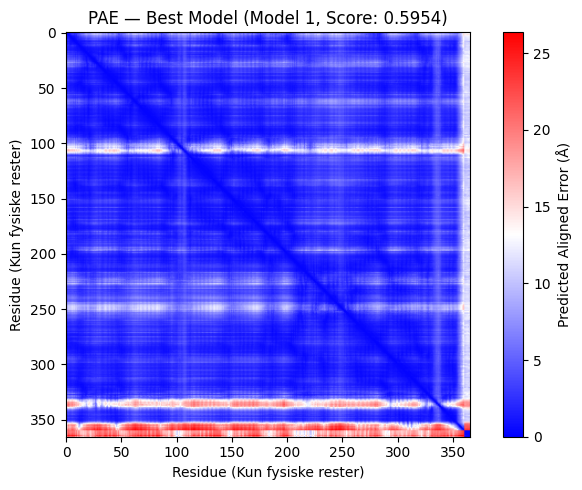

In [ ]:
# @title Plot PAE for the best model (highest aggregate score) - Kun fysiske rester
import matplotlib.pyplot as plt
import numpy as np
from Bio.PDB.MMCIFParser import MMCIFParser

# Find the model with the highest aggregate score
best_model_idx = None
best_score = -1.0

for i in range(5):
    try:
        s = np.load(output_dir / f"scores.model_idx_{i}.npz")
        if "aggregate_score" in s.files:
            score = s["aggregate_score"].item()
            if score > best_score:
                best_score = score
                best_model_idx = i
    except Exception as e:
        pass

if best_model_idx is not None:
    print(f"Best model found: Model {best_model_idx} with aggregate score: {best_score:.4f}")

    # Bestem residu-antal dynamisk for at undgå NameError
    try:
        selected_model_path = sorted(output_dir.glob("pred.model_idx_*.cif"))[best_model_idx]
        parser = MMCIFParser(QUIET=True)
        structure = parser.get_structure("model", selected_model_path)
        model_struct = structure[0]
        c_a_count = len(list(model_struct['A'].get_residues()))
        c_b_count = len(list(model_struct['B'].get_residues()))
    except Exception as e:
        # Fallback hvis filerne ikke kan parses
        c_a_count = 135
        c_b_count = 7

    # Plot PAE for the best model
    plt.figure(figsize=(7, 5))
    if candidates.pae is not None and best_model_idx < len(candidates.pae):
        pae = candidates.pae[best_model_idx]
        pae = np.asarray(pae)
        if pae.ndim == 3:
            pae = pae[0]

        # Slices til kun fysiske rester (142 tokens)
        total_physical_residues = c_a_count + c_b_count
        pae_physical = pae[:total_physical_residues, :total_physical_residues]

        plt.imshow(pae_physical, cmap="bwr", vmin=0, vmax=min(30, np.nanmax(pae_physical)))
        plt.colorbar(label="Predicted Aligned Error (Å)")
        plt.xlabel("Residue (Kun fysiske rester)")
        plt.ylabel("Residue (Kun fysiske rester)")
        plt.title(f"PAE — Best Model (Model {best_model_idx}, Score: {best_score:.4f})")
        plt.tight_layout()
        plt.savefig(output_dir / f"pae_best_model_{best_model_idx}.png", dpi=150)
        plt.show()
    else:
        print(f"PAE data for the best model {best_model_idx} is not available.")
else:
    print("Could not determine the best model from the scores files.")

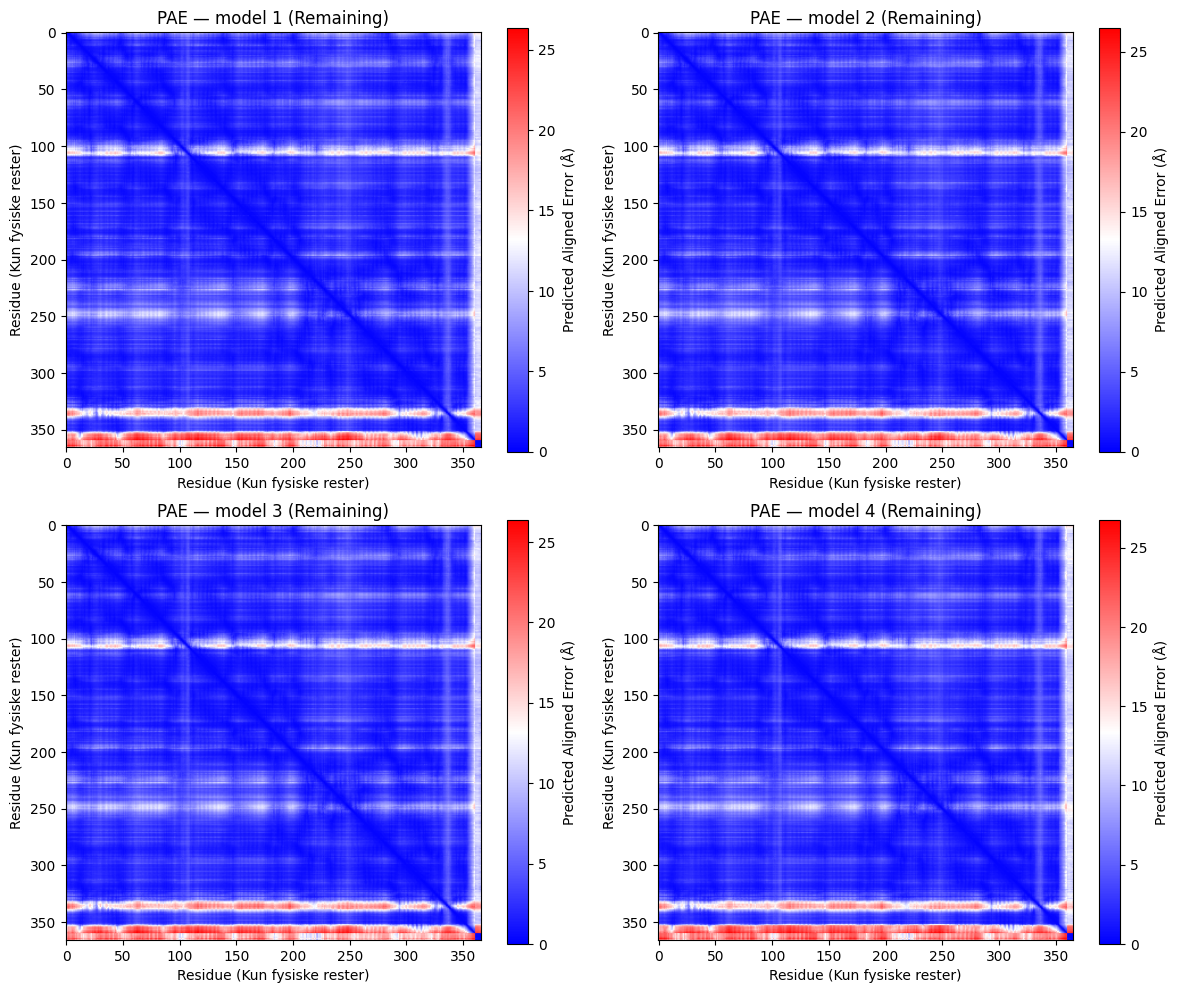

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [ ]:
# @title Plot remaining 4 models (top2-5) - Kun fysiske rester
import matplotlib.pyplot as plt
import numpy as np
from Bio.PDB.MMCIFParser import MMCIFParser

# The remaining models after excluding the best model (model 0)
remaining_models_indices = [1, 2, 3, 4]
num_plots = len(remaining_models_indices)

# Create a figure with a 2x2 layout for the 4 remaining models
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten()

for plot_idx, model_idx in enumerate(remaining_models_indices):
    ax = axes[plot_idx]
    # Access PAE from the candidates object for the current model_idx
    if candidates.pae is not None and model_idx < len(candidates.pae):
        pae = candidates.pae[model_idx]
        pae = np.asarray(pae)
        if pae.ndim == 3:
            pae = pae[0]

        # Dynamisk parsing af residu-antal for den specifikke model for at undgå NameError
        try:
            selected_model_path = sorted(output_dir.glob("pred.model_idx_*.cif"))[model_idx]
            parser = MMCIFParser(QUIET=True)
            structure = parser.get_structure("model", selected_model_path)
            model_struct = structure[0]
            c_a_count = len(list(model_struct['A'].get_residues()))
            c_b_count = len(list(model_struct['B'].get_residues()))
        except Exception:
            c_a_count = 135
            c_b_count = 7

        # Slices til kun fysiske rester (142 tokens)
        total_physical_residues = c_a_count + c_b_count
        pae_physical = pae[:total_physical_residues, :total_physical_residues]

        im = ax.imshow(pae_physical, cmap="bwr", vmin=0, vmax=min(30, np.nanmax(pae_physical)))
        fig.colorbar(im, ax=ax, label="Predicted Aligned Error (Å)")
        ax.set_xlabel("Residue (Kun fysiske rester)")
        ax.set_ylabel("Residue (Kun fysiske rester)")
        ax.set_title(f"PAE — model {model_idx} (Remaining)")
    else:
        ax.set_title(f"PAE — model {model_idx} (Not available)")
        ax.text(0.5, 0.5, 'PAE data missing', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)

plt.tight_layout()
plt.savefig(output_dir / "pae_remaining_models_physical_only.png", dpi=150)
plt.show()

In [ ]:
# @title Per-residue confidence (pLDDT) - Kun fysiske rester
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from IPython.display import display
from Bio.PDB.MMCIFParser import MMCIFParser

def plot_plddt(model_idx=0):
    if 'candidates' in globals() and candidates.plddt is not None and model_idx < len(candidates.plddt):
        plddt = candidates.plddt[model_idx]
    else:
        print("pLDDT data or 'candidates' variable is not available.")
        return

    plddt = np.asarray(plddt).squeeze()
    if plddt.max() <= 1.5:
        plddt = plddt * 100

    # Dynamisk parsing af residu-antal for den specifikke model for at undgå NameError
    try:
        selected_model_path = sorted(output_dir.glob("pred.model_idx_*.cif"))[model_idx]
        parser = MMCIFParser(QUIET=True)
        structure = parser.get_structure("model", selected_model_path)
        model_struct = structure[0]
        c_a_count = len(list(model_struct['A'].get_residues()))
        c_b_count = len(list(model_struct['B'].get_residues()))
    except Exception:
        # Fallback hvis filerne ikke kan parses
        c_a_count = 135
        c_b_count = 7

    # Slice så vi KUN viser de reelle rester (Chain A + Chain B)
    total_physical_residues = c_a_count + c_b_count
    plddt_physical = plddt[:total_physical_residues]

    plt.figure(figsize=(10, 3.5))
    # Tegner begge kæder med nøjagtig samme linjestil (linewidth=1.2 og ingen markører)
    plt.plot(range(c_a_count), plddt_physical[:c_a_count], color='teal', linewidth=1.2, label="Protein (Chain A)")
    plt.plot(range(c_a_count, total_physical_residues), plddt_physical[c_a_count:], color='purple', linewidth=1.2, label="Glycan (Chain B)")

    plt.axvline(c_a_count - 0.5, color='black', linestyle='--', linewidth=1.2, label='Kædegrænse')
    plt.axhline(90, color="blue", linestyle="--", linewidth=0.8, label="Very High (90)")
    plt.axhline(70, color="cyan", linestyle="--", linewidth=0.8, label="Confident (70)")
    plt.axhline(50, color="yellow", linestyle="--", linewidth=0.8, label="Low (50)")

    plt.xlabel("Residue / Token index (Kun reelle rester)")
    plt.ylabel("pLDDT")
    plt.ylim(0, 105)
    plt.legend(fontsize=8, loc='lower left')
    plt.title(f"Per-residue confidence — model {model_idx} (Uden hj&#230;lpe-tokens)")
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(output_dir / f"plddt_physical_only_model_{model_idx}.png", dpi=150)
    plt.show()

# Opret slider til modelvalg
plddt_model_selector = widgets.IntSlider(
    min=0,
    max=4,
    step=1,
    description='Select Model:',
    value=0,
    continuous_update=False
)

display(widgets.interactive(plot_plddt, model_idx=plddt_model_selector))

interactive(children=(IntSlider(value=0, continuous_update=False, description='Select Model:', max=4), Output(…

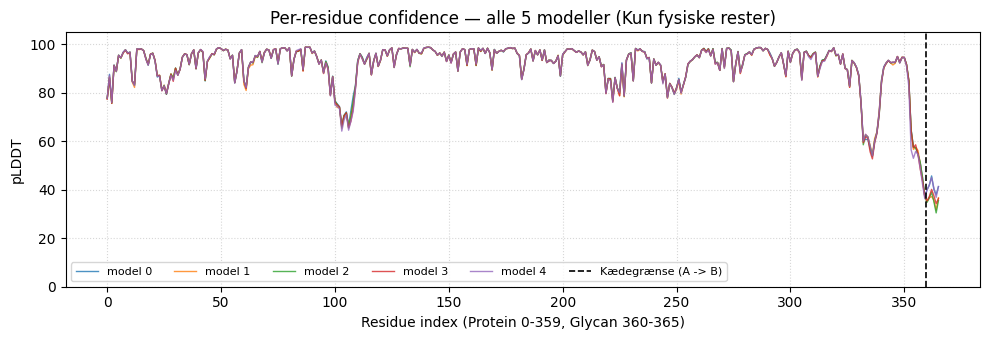

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [ ]:
# @title Per-residue confidence (pLDDT) for alle 5 modeller - Kun fysiske rester
import matplotlib.pyplot as plt
import numpy as np
from Bio.PDB.MMCIFParser import MMCIFParser

# Dynamisk og robust parsing af resterne for at undgå NameError
try:
    # Vi parser model 0 som repræsentant for at finde antallet af rester på kæde A og B
    representative_model = sorted(output_dir.glob("pred.model_idx_*.cif"))[0]
    parser = MMCIFParser(QUIET=True)
    structure = parser.get_structure("model", representative_model)
    model_struct = structure[0]
    c_a_count = len(list(model_struct['A'].get_residues()))
    c_b_count = len(list(model_struct['B'].get_residues()))
except Exception:
    c_a_count = 135
    c_b_count = 7

total_physical_residues = c_a_count + c_b_count

plt.figure(figsize=(10, 3.5))

for i in range(5):
    if 'candidates' in globals() and candidates.plddt is not None and i < len(candidates.plddt):
        p = candidates.plddt[i]
        p = np.asarray(p).squeeze()
        if p.max() <= 1.5:
            p = p * 100

        # Plot kun fysiske aminosyrer + glycaner med ensartet linjestil
        p_physical = p[:total_physical_residues]
        plt.plot(p_physical, linewidth=1.0, alpha=0.8, label=f"model {i}")

plt.axvline(c_a_count - 0.5, color='black', linestyle='--', linewidth=1.2, label='Kædegrænse (A -> B)')
plt.xlabel(f"Residue index (Protein 0-{c_a_count-1}, Glycan {c_a_count}-{total_physical_residues-1})")
plt.ylabel("pLDDT")
plt.ylim(0, 105)
plt.legend(fontsize=8, ncol=6, loc='lower left')
plt.title("Per-residue confidence — alle 5 modeller (Kun fysiske rester)")
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

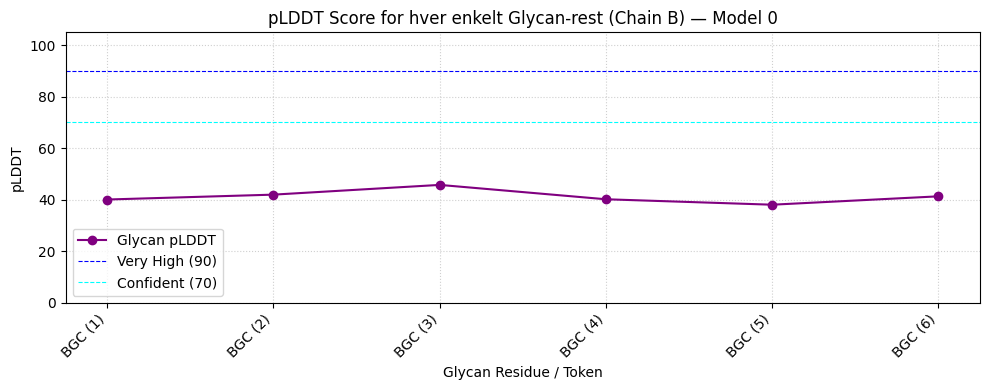

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np
from Bio.PDB.MMCIFParser import MMCIFParser

# Vi bruger den bedste model (model_idx=0) som udgangspunkt
model_idx = 0
selected_model_path = sorted(output_dir.glob("pred.model_idx_*.cif"))[model_idx]

# Parse strukturen for at finde ud af hvilke residuer der hører til Chain B (glycan)
parser = MMCIFParser(QUIET=True)
structure = parser.get_structure("model", selected_model_path)
model = structure[0]

# Find de nøjagtige residu-numre/indekser for Chain A og Chain B
chain_a_res_count = len(list(model['A'].get_residues()))
chain_b_residues = list(model['B'].get_residues())
chain_b_res_count = len(chain_b_residues)

# Hent alle pLDDT værdier
plddt_all = np.asarray(candidates.plddt[model_idx]).squeeze()
if plddt_all.max() <= 1.5:
    plddt_all = plddt_all * 100

# Glycan-resterne starter efter protein-resterne (Chain A)
glycan_plddt = plddt_all[chain_a_res_count : chain_a_res_count + chain_b_res_count]
glycan_labels = [f"{res.get_resname()} ({i+1})" for i, res in enumerate(chain_b_residues)]

# Plot glycan pLDDT
plt.figure(figsize=(10, 4))
plt.plot(glycan_plddt, marker='o', color='purple', linestyle='-', linewidth=1.5, label="Glycan pLDDT")
plt.xticks(range(len(glycan_labels)), glycan_labels, rotation=45, ha='right')
plt.axhline(90, color="blue", linestyle="--", linewidth=0.8, label="Very High (90)")
plt.axhline(70, color="cyan", linestyle="--", linewidth=0.8, label="Confident (70)")

plt.title(f"pLDDT Score for hver enkelt Glycan-rest (Chain B) — Model {model_idx}")
plt.xlabel("Glycan Residue / Token")
plt.ylabel("pLDDT")
plt.ylim(0, 105)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np
from Bio.PDB.MMCIFParser import MMCIFParser

# 1. Find den bedste model dynamisk for at undgå NameError
best_model_idx = 0
best_score = -1.0
for i in range(5):
    try:
        s = np.load(output_dir / f"scores.model_idx_{i}.npz")
        if "aggregate_score" in s.files:
            score = s["aggregate_score"].item()
            if score > best_score:
                best_score = score
                best_model_idx = i
    except Exception:
        pass

# 2. Hent pLDDT for den bedste model
try:
    plddt_all = np.asarray(candidates.plddt[best_model_idx]).squeeze()
    if plddt_all.max() <= 1.5:
        plddt_all = plddt_all * 100
except NameError:
    plddt_all = np.zeros(142)  # Fallback hvis data mangler

# 3. Bestem residu-antal dynamisk fra .cif filen
try:
    selected_model_path = sorted(output_dir.glob("pred.model_idx_*.cif"))[best_model_idx]
    parser = MMCIFParser(QUIET=True)
    structure = parser.get_structure("model", selected_model_path)
    model = structure[0]
    chain_a_res_count = len(list(model['A'].get_residues()))
    chain_b_res_count = len(list(model['B'].get_residues()))
except Exception:
    chain_a_res_count = 135
    chain_b_res_count = 7

# Slices til fysiske rester
protein_plddt = plddt_all[:chain_a_res_count]
glycan_plddt = plddt_all[chain_a_res_count : chain_a_res_count + chain_b_res_count]

# Beregn statistikker
mean_protein = np.mean(protein_plddt)
mean_glycan = np.mean(glycan_plddt)

print(f"Gennemsnitlig pLDDT for Proteinkæden (Chain A): {mean_protein:.1f}")
print(f"Gennemsnitlig pLDDT for Glycanen (Chain B):      {mean_glycan:.1f}")

# Lav et grid med to sammenligningsfigurer
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 2.5]})

# Fig 1: Boxplot sammenligning
axes[0].boxplot([protein_plddt, glycan_plddt], tick_labels=['Protein (Chain A)', 'Glycan (Chain B)'], patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='red', linewidth=1.5))
axes[0].set_ylabel("pLDDT Score")
axes[0].set_ylim(0, 105)
axes[0].set_title("Overordnet Fordeling af pLDDT")
axes[0].grid(True, linestyle=':', alpha=0.6)

# Fig 2: Samlet profil med skillelinje (ensartet linjestil for begge kæder)
axes[1].plot(range(len(protein_plddt)), protein_plddt, color='teal', label='Protein residues', alpha=0.8, linewidth=1.2)
glycan_indices = range(chain_a_res_count, chain_a_res_count + chain_b_res_count)
axes[1].plot(glycan_indices, glycan_plddt, color='purple', label='Glycan residues', linewidth=1.2)
axes[1].axvline(chain_a_res_count - 0.5, color='black', linestyle='--', linewidth=1.2, label='Kædegrænse (A -> B)')

axes[1].axhline(90, color="blue", linestyle=":", linewidth=0.8, label="Very High (90)")
axes[1].axhline(70, color="cyan", linestyle=":", linewidth=0.8, label="Confident (70)")

axes[1].set_xlabel("Sekvens-index (Residue/Token Index)")
axes[1].set_ylabel("pLDDT")
axes[1].set_xlim(0, chain_a_res_count + chain_b_res_count + 5)
axes[1].set_ylim(0, 105)
axes[1].set_title("Samlet pLDDT Profil (Protein + Glycan)")
axes[1].legend(loc='lower left', fontsize=9)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle(f"Sammenligning af pLDDT-score (Model {best_model_idx})", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

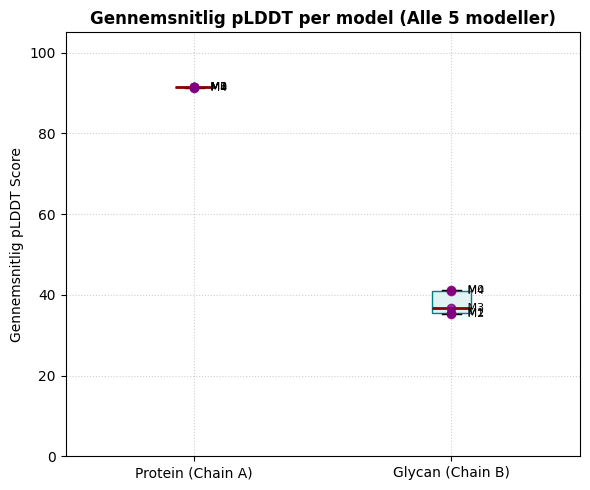

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning:

datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).



In [ ]:
# @title
import matplotlib.pyplot as plt
import numpy as np

protein_averages = []
glycan_averages = []

for i in range(5):
    if candidates.plddt is not None and i < len(candidates.plddt):
        plddt_vals = np.asarray(candidates.plddt[i]).squeeze()
        if plddt_vals.max() <= 1.5:
            plddt_vals = plddt_vals * 100

        # Beregn gennemsnit for fysiske rester
        prot_mean = np.mean(plddt_vals[:chain_a_res_count])
        glyc_mean = np.mean(plddt_vals[chain_a_res_count : chain_a_res_count + chain_b_res_count])

        protein_averages.append(prot_mean)
        glycan_averages.append(glyc_mean)

# Lav boxplot til at sammenligne gennemsnit på tværs af alle 5 modeller
plt.figure(figsize=(6, 5))
plt.boxplot([protein_averages, glycan_averages], tick_labels=['Protein (Chain A)', 'Glycan (Chain B)'], patch_artist=True,
            boxprops=dict(facecolor='#e0f2f1', color='teal'),
            medianprops=dict(color='darkred', linewidth=2))

# Tilføj de rå datapunkter for hver model ovenpå boxplottet
for idx, (p_avg, g_avg) in enumerate(zip(protein_averages, glycan_averages)):
    plt.scatter([1, 2], [p_avg, g_avg], color='purple', zorder=3, alpha=0.8, label=f'Model {idx}' if idx == 0 else "")
    plt.text(1 + 0.05, p_avg, f" M{idx}", fontsize=8, verticalalignment='center')
    plt.text(2 + 0.05, g_avg, f" M{idx}", fontsize=8, verticalalignment='center')

plt.ylabel("Gennemsnitlig pLDDT Score")
plt.ylim(0, 105)
plt.title("Gennemsnitlig pLDDT per model (Alle 5 modeller)", weight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
# @title #Visualize the models in the notebook
!pip install -q py3Dmol biopython
import py3Dmol
from pathlib import Path
import ipywidgets as widgets
from IPython.display import display
from Bio.PDB.MMCIFParser import MMCIFParser
from Bio.PDB import NeighborSearch
import numpy as np

output_dir = Path(f"/content/{output_folder_basename}/input_glycan_1")

def display_protein_model(model_idx=0):
    cif_files = sorted(output_dir.glob("pred.model_idx_*.cif"))
    if not cif_files:
        print(f"No CIF files found in {output_dir}.")
        return

    selected_model_path = cif_files[model_idx]
    print("Showing:", selected_model_path)

    # Hent pLDDT for denne model
    plddt_vals = np.asarray(candidates.plddt[model_idx]).squeeze()
    if plddt_vals.max() <= 1.5:
        plddt_vals = plddt_vals * 100

    # Parse struktur for kæde-oplysninger
    parser = MMCIFParser(QUIET=True)
    structure = parser.get_structure("model", selected_model_path)
    model = structure[0]

    chain_a_res = list(model['A'].get_residues())
    chain_b_res = list(model['B'].get_residues())

    view = py3Dmol.view(width=1000, height=800)
    with open(selected_model_path) as f:
        view.addModel(f.read(), "cif")

    # Funktion til at vælge farve ud fra pLDDT score
    def get_plddt_color(score):
        if score >= 90: return "#0053D6" # Mørkeblå
        elif score >= 70: return "#65C5F4" # Lyseblå
        elif score >= 50: return "#FFDF00" # Gul
        else: return "#FF6000" # Orange/Rød

    # Farvelæg proteinet (Chain A) per residue baseret på pLDDT
    for i, res in enumerate(chain_a_res):
        res_id = res.get_id()[1]
        score = plddt_vals[i] if i < len(plddt_vals) else 0
        view.setStyle({"chain": "A", "resi": str(res_id)}, {"cartoon": {"color": get_plddt_color(score)}})

    # Farvelæg glycanen (Chain B) per residue baseret på pLDDT
    for i, res in enumerate(chain_b_res):
        res_id = res.get_id()[1]
        val_idx = len(chain_a_res) + i
        score = plddt_vals[val_idx] if val_idx < len(plddt_vals) else 0
        view.setStyle({"chain": "B", "resi": str(res_id)}, {"cartoon": {"color": get_plddt_color(score)}})

    # --- Highlight kontakt-rester indenfor 6Å af glycanen ---
    glycan_atoms = [atom for res in chain_b_res for atom in res.get_atoms()]
    if glycan_atoms:
        all_atoms = [atom for atom in model.get_atoms()]
        ns = NeighborSearch(all_atoms)
        highlighted_res = set()
        atom_colors = {"C": "lightgrey", "N": "blue", "O": "red"}

        for glycan_atom in glycan_atoms:
            close_atoms = ns.search(glycan_atom.get_coord(), 6.0)
            for atom in close_atoms:
                res = atom.get_parent()
                if res.get_parent().id == 'A':
                    if res not in highlighted_res:
                        view.addStyle({"chain": "A", "resi": str(res.get_id()[1])},
                                      {"stick": {"colorscheme": {"prop": "atom", "map": atom_colors}, "radius": 0.15}})
                        highlighted_res.add(res)

    view.zoomTo()
    view.show()

model_selector = widgets.IntSlider(
    min=0,
    max=4,
    step=1,
    description='Select Model:',
    value=0,
    continuous_update=False
)

display(widgets.interactive(display_protein_model, model_idx=model_selector))

interactive(children=(IntSlider(value=0, continuous_update=False, description='Select Model:', max=4), Output(…

In [ ]:
import shutil
from pathlib import Path
from google.colab import files

output_dir = Path("/content/output_glycan-run005")   # ← folder with your glycan subfolders

zip_path = shutil.make_archive(
    "/content/chai_outputs_results",   # output zip name (no .zip)
    "zip",
    output_dir.parent,                 # root dir  ← keeps subfolders intact
    output_dir.name,                   # dir to zip
)

print(f"Zipped: {zip_path}")
files.download(zip_path)

FileNotFoundError: [Errno 2] No such file or directory: '/content/output_glycan-run005'

In [ ]:
# @title Download 3D models
import shutil
from google.colab import files

# Ensure output_dir is defined. It should be from a previous cell's execution.
# If not, you might need to run the cell that defines `output_dir` (e.g., r5fH3iYn_k0E) first.
# For this context, assuming output_dir is already set to '/content/outputs'.

zip_path = shutil.make_archive(output_folder_basename, "zip", output_dir)
print(f"Downloading {zip_path.split('/')[-1]}...")
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>